# Alignement de séquences par programmation dynamique

Ce carnet ouvre le pli **Séquences** de la série **Bio & Médecine**. Deux séquences se comparent en choisissant, parmi toutes les façons de les mettre colonne par colonne, celle qui donne le meilleur score. Le carnet écrit à la main les deux algorithmes qui résolvent ce problème — l'alignement **global**, qui compare deux séquences d'un bout à l'autre, et l'alignement **local**, qui cherche leur meilleur tronçon commun — avec une matrice de substitution construite depuis un modèle probabiliste déclaré, et des brèches dont le coût dépend de leur longueur.

Le point de départ est un constat d'énumération : le nombre d'alignements croît trop vite pour qu'on les passe tous en revue au-delà de quelques lettres, alors qu'un score optimal se calcule case par case. Toute la question est de savoir si le calcul case par case rend bien le maximum de l'énumération. Le carnet ne le suppose pas : il écrit les deux, et il les confronte.

Le carnet applique le contrat de méthode de la série :

1. **Modèle** — il énonce ce qu'est un alignement, ce qu'est son score, et les hypothèses que ce score suppose.
2. **Calcul** — il écrit les deux récurrences à partir de zéro, sans bibliothèque d'alignement.
3. **Contrôle indépendant** — il compare le calcul à deux voies qui ne partagent pas son code : l'énumération de tous les alignements sur de petites instances, et la bibliothèque de référence sur des séquences protéiques publiques.
4. **Contre-témoin** — il construit trois cas où un contrôle doit rendre un verdict négatif : un alignement glouton, une récurrence fautive, une matrice décalée.
5. **Statut** — il sépare ce qui est mesuré ici, ce qui est cité d'une source, et ce qui reste ouvert.

Aucune séquence n'est recopiée dans le dépôt. Les données simulées viennent d'un processus de mutation déclaré, à vérité connue ; les séquences réelles sont chargées à l'exécution depuis la NCBI.

## Ce que ce carnet établit, et ce qu'il n'établit pas

| Section | Question | Contrôle indépendant | Contre-témoin |
|---|---|---|---|
| 2 et 3 | La récurrence rend-elle le maximum des alignements, et pas seulement un bon score ? | Énumération de **tous** les alignements, sur toutes les paires de courtes séquences | Une récurrence fautive (prolongation de brèche oubliée) doit être relevée par ce même contrôle |
| 4 | Une matrice de scores est-elle arbitraire ? | Score moyen d'une paire vraie mesuré sur des paires simulées, contre son information mutuelle calculée ; matrice reconstruite par comptage et comparée à la matrice calculée | Une matrice trop raide doit récupérer moins bien que la matrice ajustée — et c'est mesuré, pas supposé |
| 5 | Retrouve-t-on les sites homologues sur des séquences à histoire connue ? | Statistiques mesurées de la simulation contre les paramètres qu'elle déclare, puis récupération des sites homologues | À grande distance, l'alignement optimal cesse de retrouver la vérité : le contrôle de vérité doit y échouer |
| 6 | Les conventions de brèches sont-elles les bonnes ? | `Bio.Align.PairwiseAligner` sur quatre protéines publiques, en global et en local | La récurrence fautive doit diverger de la bibliothèque |

**Ce que la feuille apporte au pli.** Un alignement est la première opération du pli : sans lui, on ne sait pas dire que deux séquences se correspondent, et les feuilles suivantes — recherche de motif, matrices de poids positionnelles, modèles de profil — n'ont pas de point de départ. La feuille apporte aussi la forme de contrôle qui leur servira : une définition qu'on énumère, une bibliothèque qui juge, et un cas où le juge doit échouer.

**Ce que le carnet n'établit pas.** Il ne dit rien de la **signification statistique** d'un score : combien vaut un score de plus qu'un autre entre deux séquences sans parenté est une autre théorie. Il n'écrit aucune **heuristique de recherche** dans une base : les récurrences sont exactes, et leur coût interdit de les appliquer telles quelles à grande échelle. Il ne dit rien non plus de l'**homologie** biologique : un score élevé est un fait arithmétique entre deux chaînes de lettres, pas une preuve d'ancêtre commun.

## Outils et conventions

Le carnet utilise `numpy` pour les tableaux, `matplotlib` pour une figure, et **Biopython** pour deux choses différentes : sa matrice **BLOSUM62**, et son aligneur `Bio.Align.PairwiseAligner`, pris comme **juge** de la section 6. La récurrence, elle, est écrite ici — c'est une copie pédagogique déclarée, comme le veut la règle de la série : la bibliothèque possède déjà le moteur, le carnet le réécrit pour qu'on voie ce qu'il fait, et s'en sert ensuite comme contrôle.

**Conventions de score.** Plus le score est grand, meilleur est l'alignement. Les pénalités de brèche sont négatives. Une brèche de longueur $k$ coûte $g_o + (k-1)\,g_e$ : l'ouverture $g_o$ est payée une fois, la prolongation $g_e$ à chaque lettre suivante. En alignement global, les brèches d'extrémité sont payées comme les autres. En alignement local, chaque case est planchée à zéro. Ces conventions ne sont pas supposées : la section 6 mesure celle de la bibliothèque avant toute comparaison.

**Données.** Les séquences simulées sont tirées sous un processus déclaré en section 5. Les quatre séquences réelles de la section 6 sont chargées à l'exécution depuis les *E-utilities* de la NCBI et **ne sont pas recopiées** dans le dépôt ; leurs numéros d'accès sont donnés en clair, pour que l'exécution soit reproductible.

In [1]:
import io
import time
import urllib.request
from functools import lru_cache
from itertools import product
from math import comb

import numpy as np
import matplotlib.pyplot as plt
import Bio
from Bio import Align, SeqIO
from Bio.Align import substitution_matrices

plt.rcParams.update({
    'figure.figsize': (7.5, 4.2),
    'axes.grid': True,
    'grid.alpha': 0.3,
    'font.size': 10,
})

print(f'numpy {np.__version__} | biopython {Bio.__version__}')

numpy 2.4.6 | biopython 1.88


## 1. Le modèle : un score additif sur les chemins d'une grille

Deux séquences, $a$ de longueur $n$ et $b$ de longueur $m$, sont écrites l'une en lignes, l'autre en colonnes, d'une grille à $n$ lignes et $m$ colonnes. Un **alignement** est une façon de parcourir cette grille de $(0,0)$ jusqu'à $(n,m)$ : un pas en diagonale apparie une lettre de $a$ à une lettre de $b$, un pas vers le bas laisse une lettre de $a$ seule, un pas vers la droite laisse une lettre de $b$ seule. Une lettre seule est une **brèche** ; des brèches consécutives dans le même sens forment un **segment de brèche**.

Le **score** d'un alignement est une somme :

$$S(\text{alignement}) = \sum_{\text{colonnes appariées}} s(a_i, b_j) \;-\; \sum_{\text{segments de brèche}} \big(g_o + (k-1)\,g_e\big)$$

où $s$ est la **matrice de substitution**, $g_o$ le coût d'**ouverture** d'un segment de brèche et $g_e$ le coût de **prolongation** de chacune de ses $k-1$ lettres suivantes. Trois hypothèses sont posées, et elles sont fortes :

- **Additivité.** Le score d'une colonne ne dépend que de ses deux lettres, jamais de ses voisines. Une protéine ne se replie pas colonne par colonne : ce modèle ne le sait pas.
- **Brèches affines.** Un long segment coûte moins cher par lettre qu'un court, pourvu que $g_o < g_e < 0$. C'est une convention, et c'est elle que la section 6 vérifie avant tout.
- **Deux optima, pas un.** L'alignement **global** compare les séquences d'un bout à l'autre : le chemin va de $(0,0)$ à $(n,m)$, brèches d'extrémité comprises. L'alignement **local** cherche la meilleure paire de sous-chaînes : c'est le maximum du score global sur tous les choix de sous-chaînes.

L'alignement optimal est celui de score maximal. Plusieurs alignements peuvent atteindre ce maximum ; le carnet énonce toujours lequel il renvoie.

Les deux alphabets et la petite table de scores déclarée, qui serviront au contrôle par énumération :

In [2]:
# Alphabet des vingt acides amines standards, une lettre, en ordre alphabetique.
ALPHABET = 'ACDEFGHIKLMNPQRSTVWY'
indice = {x: i for i, x in enumerate(ALPHABET)}

# Petit alphabet et petite table declares, pour le controle par enumeration (section 3).
PETIT = 'AC'
SCORE_AC = {('A', 'A'): 2.0, ('C', 'C'): 2.0, ('A', 'C'): -1.0, ('C', 'A'): -1.0}
OUV_AC, EXT_AC = -2.0, -0.5


def score_ac(x, y):
    # Score declare d'un appariement sur le petit alphabet.
    return SCORE_AC[(x, y)]


print(f'{len(ALPHABET)} lettres | petit alphabet {PETIT} | ouverture {OUV_AC} | extension {EXT_AC}')

20 lettres | petit alphabet AC | ouverture -2.0 | extension -0.5


## 2. La récurrence, avec brèches affines

Énumérer tous les chemins est hors de portée dès que les séquences dépassent quelques lettres. La programmation dynamique exploite une propriété du score additif : le début d'un chemin optimal est optimal pour la case où il arrive — **à condition de retenir dans quel état il y arrive**. Comme le coût d'une brèche dépend de son rang dans son segment, l'état distingue trois situations. Pour chaque case $(i,j)$ :

$$M_{i,j} = s(a_i,b_j) + \max\big(M_{i-1,j-1},\, X_{i-1,j-1},\, Y_{i-1,j-1}\big)$$

$$X_{i,j} = \max\big(M_{i-1,j} + g_o,\; X_{i-1,j} + g_e\big) \qquad Y_{i,j} = \max\big(M_{i,j-1} + g_o,\; Y_{i,j-1} + g_e\big)$$

- $M_{i,j}$ : meilleur score d'un chemin arrivant en $(i,j)$ **par un appariement** ;
- $X_{i,j}$ : meilleur score arrivant par une **brèche dans $b$** (la lettre $a_i$ est seule) ;
- $Y_{i,j}$ : meilleur score arrivant par une **brèche dans $a$** (la lettre $b_j$ est seule).

Ouvrir une brèche se fait depuis $M$ ; la prolonger depuis l'état de brèche de même sens. Une brèche dans $b$ suivie immédiatement d'une brèche dans $a$ n'est jamais optimale : elle paierait deux ouvertures sans apparier une seule lettre. L'initialisation pose $M_{0,0} = 0$ et, sur les bords, une unique brèche payée en entier. L'alignement global vaut le maximum des trois états en $(n,m)$.

Pour l'alignement **local**, chaque état est planché à zéro : une case à zéro est un point de départ, et le maximum de $M$ sur toute la grille est le score local. Un alignement local ne commence ni ne finit par une brèche : cela coûterait sans rien apparier.

In [3]:
def alignement_global(a, b, score, ouverture, extension):
    """Alignement global optimal, a breches affines.

    Renvoie (score, chemin, tables). Une breche de longueur k coute
    ouverture + (k - 1) * extension ; le chemin est une liste de couples (i, j)
    ou None marque une lettre seule.
    """
    n, m = len(a), len(b)
    M = np.full((n + 1, m + 1), -np.inf)
    X = np.full((n + 1, m + 1), -np.inf)
    Y = np.full((n + 1, m + 1), -np.inf)
    PM = np.zeros((n + 1, m + 1), dtype=np.int8)   # etat precedent de M   : 0 = M, 1 = X, 2 = Y
    PX = np.zeros((n + 1, m + 1), dtype=np.int8)   # provenance de X       : 0 = ouverture (M), 1 = prolongation (X)
    PY = np.zeros((n + 1, m + 1), dtype=np.int8)   # provenance de Y       : 0 = ouverture (M), 1 = prolongation (Y)
    M[0, 0] = 0.0
    # Bords : une seule breche, payee en entier (ouverture puis prolongations).
    for i in range(1, n + 1):
        X[i, 0] = ouverture + (i - 1) * extension
        PX[i, 0] = 1 if i > 1 else 0
    for j in range(1, m + 1):
        Y[0, j] = ouverture + (j - 1) * extension
        PY[0, j] = 1 if j > 1 else 0
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            # X : colonne ou a[i-1] est seule (breche dans b).
            ouv, ext = M[i - 1, j] + ouverture, X[i - 1, j] + extension
            if ouv >= ext:
                X[i, j], PX[i, j] = ouv, 0
            else:
                X[i, j], PX[i, j] = ext, 1
            # Y : colonne ou b[j-1] est seule (breche dans a).
            ouv, ext = M[i, j - 1] + ouverture, Y[i, j - 1] + extension
            if ouv >= ext:
                Y[i, j], PY[i, j] = ouv, 0
            else:
                Y[i, j], PY[i, j] = ext, 1
            # M : colonne appariee, apres n'importe quel etat.
            trois = (M[i - 1, j - 1], X[i - 1, j - 1], Y[i - 1, j - 1])
            k = int(np.argmax(trois))
            M[i, j], PM[i, j] = trois[k] + score(a[i - 1], b[j - 1]), k
    finaux = (M[n, m], X[n, m], Y[n, m])
    etat = int(np.argmax(finaux))
    # Remontee : chaque tableau de pointeurs dit dans quel etat se trouve la case precedente.
    chemin = []
    i, j = n, m
    while i > 0 or j > 0:
        if etat == 0:
            chemin.append((i - 1, j - 1))
            etat, i, j = int(PM[i, j]), i - 1, j - 1
        elif etat == 1:
            chemin.append((i - 1, None))
            etat, i = (1 if PX[i, j] == 1 else 0), i - 1
        else:
            chemin.append((None, j - 1))
            etat, j = (2 if PY[i, j] == 1 else 0), j - 1
    chemin.reverse()
    return float(finaux[int(np.argmax(finaux))]), chemin, {'M': M, 'X': X, 'Y': Y}

In [4]:
def alignement_local(a, b, score, ouverture, extension):
    """Alignement local optimal : maximum sur tous les couples de sous-chaines."""
    n, m = len(a), len(b)
    M = np.zeros((n + 1, m + 1))
    X = np.zeros((n + 1, m + 1))
    Y = np.zeros((n + 1, m + 1))
    PM = np.zeros((n + 1, m + 1), dtype=np.int8)   # etat precedent de M : -1 = depart, 0 = M, 1 = X, 2 = Y
    PX = np.zeros((n + 1, m + 1), dtype=np.int8)   # provenance de X       : -1 = depart, 0 = ouverture, 1 = prolongation
    PY = np.zeros((n + 1, m + 1), dtype=np.int8)   # provenance de Y       : -1 = depart, 0 = ouverture, 1 = prolongation
    meilleur = (0.0, 0, 0)
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            # Les trois etats sont planches a zero : une remise a zero est un demarrage.
            ouv, ext = M[i - 1, j] + ouverture, X[i - 1, j] + extension
            if max(0.0, ouv, ext) == 0.0:
                X[i, j], PX[i, j] = 0.0, -1
            elif ouv >= ext:
                X[i, j], PX[i, j] = ouv, 0
            else:
                X[i, j], PX[i, j] = ext, 1
            ouv, ext = M[i, j - 1] + ouverture, Y[i, j - 1] + extension
            if max(0.0, ouv, ext) == 0.0:
                Y[i, j], PY[i, j] = 0.0, -1
            elif ouv >= ext:
                Y[i, j], PY[i, j] = ouv, 0
            else:
                Y[i, j], PY[i, j] = ext, 1
            trois = (M[i - 1, j - 1], X[i - 1, j - 1], Y[i - 1, j - 1])
            k = int(np.argmax(trois))
            valeur = trois[k] + score(a[i - 1], b[j - 1])
            if valeur <= 0.0:
                M[i, j], PM[i, j] = 0.0, -1
            else:
                M[i, j], PM[i, j] = valeur, k
                if valeur > meilleur[0]:
                    meilleur = (valeur, i, j)
    score_best, i, j = meilleur
    # Remontee depuis la meilleure case, jusqu'a une case remise a zero.
    chemin = []
    etat = 0
    while True:
        if etat == 0:
            if M[i, j] <= 0.0:
                break
            chemin.append((i - 1, j - 1))
            etat, i, j = int(PM[i, j]), i - 1, j - 1
        elif etat == 1:
            if X[i, j] <= 0.0:
                break
            chemin.append((i - 1, None))
            etat, i = (1 if PX[i, j] == 1 else int(PX[i, j])), i - 1
        else:
            if Y[i, j] <= 0.0:
                break
            chemin.append((None, j - 1))
            etat, j = (2 if PY[i, j] == 1 else int(PY[i, j])), j - 1
        if etat < 0:
            break
    chemin.reverse()
    return float(score_best), chemin, {'M': M, 'X': X, 'Y': Y}

In [5]:
def score_chemin(a, b, chemin, score, ouverture, extension):
    """Recompte le score d'un chemin colonne par colonne, sans lire les tables.

    C'est la definition du score, ecrite une seconde fois : le controle par
    enumeration s'en sert, la recursion ne l'appelle jamais.
    """
    total = 0.0
    longueur, sens = 0, None
    for i, j in chemin:
        if i is None or j is None:
            # Colonne de breche : on compte un segment, pas une lettre.
            nouveau = (i is not None)
            if sens == nouveau:
                longueur += 1
            else:
                sens, longueur = nouveau, 1
            total += ouverture if longueur == 1 else extension
        else:
            sens, longueur = None, 0
            total += score(a[i], b[j])
    return total


def est_un_alignement(a, b, chemin):
    """Verifie que le chemin est un alignement global de a et b : lettres dans l'ordre, toutes presentes."""
    indices_a = [i for i, j in chemin if i is not None]
    indices_b = [j for i, j in chemin if j is not None]
    if any(not 0 <= i < len(a) for i in indices_a) or any(not 0 <= j < len(b) for j in indices_b):
        return False
    return ''.join(a[i] for i in indices_a) == a and ''.join(b[j] for j in indices_b) == b


def est_un_alignement_local(a, b, chemin):
    """Verifie qu'un chemin local est un alignement global d'une sous-chaine de a et d'une sous-chaine de b."""
    if not chemin:
        return True
    indices_a = [i for i, j in chemin if i is not None]
    indices_b = [j for i, j in chemin if j is not None]
    i0, i1 = min(indices_a), max(indices_a) + 1
    j0, j1 = min(indices_b), max(indices_b) + 1
    translate = [(None if i is None else i - i0, None if j is None else j - j0) for i, j in chemin]
    return est_un_alignement(a[i0:i1], b[j0:j1], translate)

### Lecture du code : ce qui est invariant, et ce qui ne l'est pas

Trois choses sont à garder en tête avant les contrôles.

**Le score est l'invariant, pas le chemin.** Quand plusieurs chemins atteignent le maximum, la fonction en renvoie un seul : celui que choisit l'ordre d'évaluation du `max` — l'appariement d'abord, puis la brèche dans $b$, puis la brèche dans $a$ ; à l'intérieur d'un état de brèche, l'ouverture avant la prolongation. Un autre programme, et la bibliothèque de la section 6, peuvent renvoyer un autre chemin de même score. C'est pourquoi les contrôles portent sur le score, et vérifient ensuite que le chemin rendu est bien un alignement des deux séquences, de score égal.

**`score_chemin` ne lit pas les tables.** Elle recompte le score d'un chemin colonne par colonne, sans rien savoir de la récurrence. C'est la définition du score, écrite une seconde fois, indépendamment de la première.

**Le coût est en $n \times m$.** Trois tableaux de $(n+1)\times(m+1)$ nombres et un double parcours. Rien n'est fait pour économiser la mémoire : à deux cents lettres, la question ne se pose pas.

## 3. Contrôle indépendant : énumérer tous les alignements

La récurrence pourrait se tromper de deux façons : rendre un score trop bas — elle aurait manqué un chemin — ou trop haut — elle aurait mal compté un chemin. Les deux erreurs sont visibles sur une définition qui n'utilise pas la récurrence : **le score optimal est le maximum des scores de tous les chemins**, chacun recompté par `score_chemin`.

Sur un alphabet de deux lettres, toutes les séquences de un à quatre caractères se listent, et pour chaque paire tous les chemins s'énumèrent par récurrence sur la grille. Le contrôle compare, pour chaque paire, ce maximum au score de la récurrence, et vérifie que le chemin rendu est un alignement valide de même score.

**Le contrôle se contrôle lui-même.** Le nombre de chemins d'une grille $(n,m)$ se calcule sans énumérer : c'est le nombre de Delannoy, $D(n,m) = \sum_k \binom{n}{k}\binom{m}{k}2^k$. Si l'énumérateur produisait trop peu de chemins, la formule le dirait — un énumérateur incomplet passerait sinon pour un contrôle.

Pour l'alignement local, le contrôle énumère tous les couples de sous-chaînes et prend le maximum de leurs scores globaux : c'est la définition posée en section 1.

In [6]:
def tous_les_chemins(n, m):
    """Tous les chemins de (0, 0) a (n, m) : pas diagonal, vers le bas, vers la droite."""
    if n == 0 and m == 0:
        yield []
    if n > 0 and m > 0:
        for prefixe in tous_les_chemins(n - 1, m - 1):
            yield prefixe + [(n - 1, m - 1)]
    if n > 0:
        for prefixe in tous_les_chemins(n - 1, m):
            yield prefixe + [(n - 1, None)]
    if m > 0:
        for prefixe in tous_les_chemins(n, m - 1):
            yield prefixe + [(None, m - 1)]


def delannoy(n, m):
    # Nombre de chemins d'une grille n x m, par la formule fermee.
    return sum(comb(n, k) * comb(m, k) * 2 ** k for k in range(min(n, m) + 1))


@lru_cache(maxsize=None)
def optimum_enumere(a, b, score, ouverture, extension):
    """Maximum des scores de tous les alignements de a et b : la definition, sans recurrence."""
    meilleur, nombre = -np.inf, 0
    for chemin in tous_les_chemins(len(a), len(b)):
        nombre += 1
        meilleur = max(meilleur, score_chemin(a, b, chemin, score, ouverture, extension))
    return meilleur, nombre


print('grille (n, m) | chemins enumeres | formule de Delannoy')
for n, m in ((1, 1), (2, 1), (3, 2), (4, 4)):
    enumeres = sum(1 for _ in tous_les_chemins(n, m))
    print(f'({n}, {m})'.ljust(13), f'| {enumeres:15d} | {delannoy(n, m):19d}')

grille (n, m) | chemins enumeres | formule de Delannoy
(1, 1)        |               3 |                   3
(2, 1)        |               5 |                   5
(3, 2)        |              25 |                  25
(4, 4)        |             321 |                 321


In [7]:
def sequences(alphabet, n_max):
    # Toutes les sequences non vides de longueur 1 a n_max sur l'alphabet.
    return [''.join(lettres) for n in range(1, n_max + 1) for lettres in product(alphabet, repeat=n)]


def balayage_global(liste_a, liste_b):
    """Compare la recursion globale au maximum enumere, sur toutes les paires des deux listes."""
    cas, chemins, ecart, invalides = 0, 0, 0.0, 0
    for a in liste_a:
        for b in liste_b:
            score_dp, chemin_dp, _ = alignement_global(a, b, score_ac, OUV_AC, EXT_AC)
            score_enum, nombre = optimum_enumere(a, b, score_ac, OUV_AC, EXT_AC)
            cas, chemins = cas + 1, chemins + nombre
            ecart = max(ecart, abs(score_dp - score_enum))
            ecart = max(ecart, abs(score_chemin(a, b, chemin_dp, score_ac, OUV_AC, EXT_AC) - score_enum))
            if not est_un_alignement(a, b, chemin_dp):
                invalides += 1
    return cas, chemins, ecart, invalides


courtes = sequences(PETIT, 3)
cas_g, chemins_g, ecart_g, invalides_g = balayage_global(sequences(PETIT, 4), sequences(PETIT, 4))
print(f'global : {cas_g} paires, {chemins_g} alignements enumeres, ecart maximal a la recursion {ecart_g:.1e}, chemins invalides {invalides_g}')

# Local : maximum des scores globaux sur tous les couples de sous-chaines.
cas_l, ecart_l, invalides_l = 0, 0.0, 0
for a in courtes:
    for b in courtes:
        attendu = max(optimum_enumere(a[i1:i2], b[j1:j2], score_ac, OUV_AC, EXT_AC)[0]
                      for i1 in range(len(a)) for i2 in range(i1 + 1, len(a) + 1)
                      for j1 in range(len(b)) for j2 in range(j1 + 1, len(b) + 1))
        score_dp, chemin_dp, _ = alignement_local(a, b, score_ac, OUV_AC, EXT_AC)
        cas_l = cas_l + 1
        ecart_l = max(ecart_l, abs(score_dp - max(attendu, 0.0)))
        ecart_l = max(ecart_l, abs(score_chemin(a, b, chemin_dp, score_ac, OUV_AC, EXT_AC) - score_dp))
        if not est_un_alignement_local(a, b, chemin_dp):
            invalides_l += 1
print(f'local  : {cas_l} paires, ecart maximal a la recursion {ecart_l:.1e}, chemins invalides {invalides_l}')

global : 900 paires, 127180 alignements enumeres, ecart maximal a la recursion 0.0e+00, chemins invalides 0
local  : 196 paires, ecart maximal a la recursion 0.0e+00, chemins invalides 0


### Lecture du résultat

L'écart maximal entre la récurrence et l'énumération vaut `0.0` sur les deux balayages, et aucun chemin rendu n'est invalide : sur ce domaine, la récurrence rend le maximum de la définition, et pas seulement un bon score. Les `900` paires du balayage global portent `127 180` alignements énumérés ; les `196` paires du balayage local en portent d'autres, et l'accord y est aussi exact. Le nombre de chemins énumérés suit la formule de Delannoy sur chaque grille — l'énumérateur ne s'est donc pas arrêté en chemin.

Ce que ce contrôle ne peut pas dire : les deux programmes partagent la **convention** des brèches affines. Si la convention elle-même était fausse — par exemple si un segment de brèche devait payer l'ouverture à chaque lettre — l'énumération et la récurrence se tromperaient ensemble, et le contrôle ne verrait rien. C'est pourquoi la section 6 vérifie la convention contre une bibliothèque, et pourquoi la section 7 construit la récurrence fautive.

### Ce que l'entretien de Gromov apporte à cette section

Dans *The Math That Life Is (Still) Missing* (Curt Jaimungal, 23 novembre 2026, <https://www.youtube.com/watch?v=010zB6EpJYQ>, 18:24), Gromov pose le problème en ces termes : « you have a large search space, an extremely large amount of hay, and then there's one needle inside, and somehow we're able to find the needle » ; et il ajoute que si l'on se contentait de chercher « in some sort of naive fashion », « it would just take far too long ».

C'est le passage de cette section, mot pour mot : l'énumération est la **définition** — le maximum de tous les chemins — mais elle parcourt la paille, et son coût explose ; la récurrence trouve le même maximum sans l'énumérer. Le carnet mesure les deux sur un domaine où la botte de foin se compte, pour que l'accord entre les deux ne soit pas une opinion.

### Exercice 1 — l'énumération tient-elle une longueur de plus ?

Le balayage global porte sur des séquences de un à quatre caractères. Le coût de l'énumération croît comme le nombre de Delannoy, et le nombre de paires comme $4^{n}$ : chaque longueur ajoutée multiplie le travail par seize environ.

**À faire.** Rejouer le balayage global sur toutes les paires de séquences de un à cinq caractères, puis six. Mesurer le nombre de paires, le nombre total d'alignements énumérés, et le temps de chaque balayage.

**Indice.** `sequences` prend la longueur maximale en argument ; `balayage_global` rend déjà les deux premiers compteurs. Pour le temps, `time.perf_counter` encadre l'appel.

**Étape 1.** Écrire `balayage_longueur(n_max)` qui renvoie le nombre de paires, le nombre d'alignements et l'écart maximal à la récurrence.
**Étape 2.** L'appeler pour cinq et six, et chronométrer.
**Étape 3.** Conclure : jusqu'où l'énumération peut-elle servir de juge, et à partir de quelle longueur faut-il un autre contrôle ?

In [8]:
def balayage_longueur(n_max):
    # TODO etudiant : rejouer balayage_global sur sequences(PETIT, n_max) dans les deux sens
    # et renvoyer (nombre de paires, nombre d'alignements, ecart maximal) (etapes 1 et 2)
    return None


for n_max in (4, 5):
    resultat = balayage_longueur(n_max)
    if resultat is None:
        print(f'longueur {n_max} : exercice a completer')
    else:
        print(f'longueur {n_max} : {resultat[0]} paires, {resultat[1]} alignements, ecart {resultat[2]:.1e}')

longueur 4 : exercice a completer
longueur 5 : exercice a completer


## 4. La matrice de substitution : d'un modèle de mutation aux log-odds

D'où viennent les valeurs de $s$ ? La section 3 en a utilisé quatre, déclarées à la main. Une matrice réelle en a quatre cents, et elles ne sont pas arbitraires : chaque valeur est le **logarithme d'un rapport de probabilités**.

**Le modèle, déclaré.** Deux sites homologues — deux lettres qui descendent d'un même site ancestral — sont modélisés ainsi : le site garde sa lettre avec la probabilité $1-\tau$, et en prend une autre, uniformément parmi les dix-neuf restantes, avec la probabilité $\tau$. Le paramètre $\tau$ est la **distance** évolutive attendue, en substitutions par site. Le fond est uniforme : une lettre tirée au hasard sort avec la probabilité $1/20$.

**Le score.** Sous ce modèle, la probabilité d'observer le couple $(a,b)$ vaut $p_{ab} = 1-\tau$ si $a=b$, et $\tau/19$ sinon. Tirer deux lettres indépendamment au hasard donne $q_a q_b = 1/400$. Le score est le logarithme du rapport, exprimé ici en **demi-bits** :

$$s_\tau(a,b) = 2\log_2 \frac{p_{ab}}{q_a q_b}$$

Un couple attendu sous le modèle d'homologie mais rare au hasard a un score positif ; un couple plus probable au hasard que sous homologie a un score négatif. Cette matrice n'a que deux valeurs, diagonale et hors diagonale : c'est la limite d'un modèle sans chimie, et la section le mesure au lieu de le corriger.

**Ce que le contrôle vérifie.** Le score moyen d'une paire vraie se calcule par la formule : c'est $(1-\tau)\,s_\tau(a,a) + \tau\, s_\tau(a,b)$. Il doit être positif — sinon la matrice ne reconnaîtrait pas ses propres données — et il porte un nom : l'**information mutuelle** du couple de sites.

In [9]:
def matrice_jc20(tau, unites='demi_bits'):
    """Matrice log-odds du modele declare, a distance tau.

    Un site garde sa lettre avec la probabilite 1 - tau, ou en prend une autre,
    uniformement parmi les dix-neuf, avec la probabilite tau. Fond uniforme (1/20).
    """
    fond = 1.0 / 20
    S = np.full((20, 20), np.log((tau / 19.0) / fond))
    np.fill_diagonal(S, np.log((1.0 - tau) / fond))
    if unites == 'demi_bits':
        S = S * (2.0 / np.log(2.0))
    return S


def information_mutuelle(tau):
    # Score moyen d'une paire vraie, calcule par la formule, en nats.
    return (1.0 - tau) * np.log(20.0 * (1.0 - tau)) + tau * np.log(20.0 * tau / 19.0)


def score_matrice(S):
    # Encapsule une matrice numpy en fonction de score (lettre, lettre).
    return lambda x, y: float(S[indice[x], indice[y]])


def tirer_paires(tau, n, generateur):
    """Couples de sites homologues (lettre ancestrale, lettre descendante), sous le modele."""
    ancestres = generateur.integers(0, 20, size=n)
    remplacees = generateur.random(n) < tau
    decalage = generateur.integers(1, 20, size=n)
    descendantes = np.where(remplacees, (ancestres + decalage) % 20, ancestres)
    return ancestres, descendantes


generateur = np.random.default_rng(2026)
print(' tau  | information mutuelle (nats) | score moyen mesure | ecart relatif')
for tau in (0.1, 0.3, 0.6, 0.9):
    anc, desc = tirer_paires(tau, 200_000, generateur)
    mesure = float(np.mean(matrice_jc20(tau, unites='nats')[anc, desc]))
    attendu = float(information_mutuelle(tau))
    print(f'{tau:5.2f} | {attendu:27.6f} | {mesure:18.6f} | {(mesure - attendu) / attendu:+8.4f}')

 tau  | information mutuelle (nats) | score moyen mesure | ecart relatif
 0.10 |                    2.376205 |           2.374560 |  -0.0007
 0.30 |                    1.501536 |           1.508987 |  +0.0050
 0.60 |                    0.556057 |           0.559764 |  +0.0067
 0.90 |                    0.020654 |           0.020120 |  -0.0259


In [10]:
def matrice_par_comptage(anc, desc):
    """Reconstruit la matrice log-odds a partir des couples observes : la recette des matrices reelles."""
    comptes = np.zeros((20, 20))
    np.add.at(comptes, (anc, desc), 1.0)
    observe = comptes / comptes.sum()
    fond_a, fond_b = observe.sum(axis=1), observe.sum(axis=0)
    S = np.zeros((20, 20))
    vus = observe > 0
    S[vus] = np.log(observe[vus] / np.outer(fond_a, fond_b)[vus])
    return S, int((comptes == 0).sum())


calculee = matrice_jc20(0.3, unites='nats')
hors = ~np.eye(20, dtype=bool)
print('couples | cases vides | ecart maximal au calcule (nats)')
for n in (2_000, 20_000, 200_000):
    anc, desc = tirer_paires(0.3, n, generateur)
    S, vides = matrice_par_comptage(anc, desc)
    ecart = float(np.max(np.abs(S[hors] - calculee[hors])))
    print(f'{n:7d} | {vides:11d} | {ecart:32.4f}')

anc, desc = tirer_paires(0.3, 200_000, generateur)
S, _ = matrice_par_comptage(anc, desc)
print(f'comptage a 200 000 : diagonale {S[0, 0]:+.3f} contre {calculee[0, 0]:+.3f} ; hors diagonale {S[0, 1]:+.3f} contre {calculee[0, 1]:+.3f}')

couples | cases vides | ecart maximal au calcule (nats)
   2000 |          82 |                           1.2902
  20000 |           0 |                           0.9705
 200000 |           0 |                           0.2315
comptage a 200 000 : diagonale +2.638 contre +2.639 ; hors diagonale -1.225 contre -1.153


BLOSUM62 : 20 lettres | diagonale de 4 a 11 (moyenne 5.80)
           hors diagonale de -4 a 3 (moyenne -1.43) | entrees negatives 288 sur 400
modele a un parametre : tau* = 0.584 | erreur quadratique moyenne 1.52 | correlation sur les 400 entrees 0.720
ecart-type de BLOSUM62 sur ses 400 entrees : 2.19


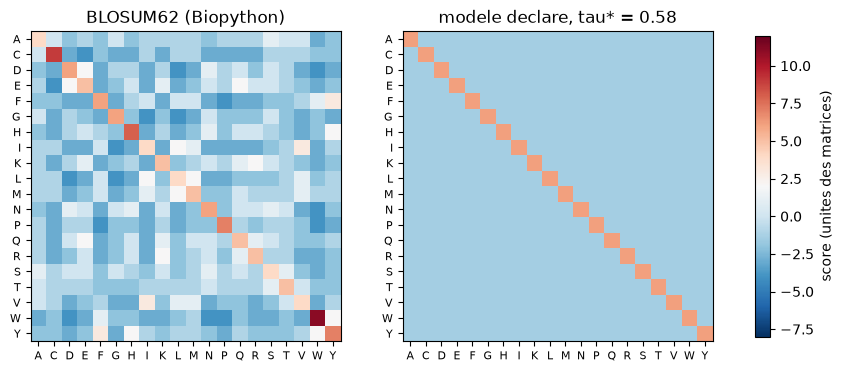

In [11]:
blosum = substitution_matrices.load('BLOSUM62')
B62 = np.array([[float(blosum[x, y]) for y in ALPHABET] for x in ALPHABET])
diagonale = np.diag(B62)
hors = B62[~np.eye(20, dtype=bool)]
print(f'BLOSUM62 : {B62.shape[0]} lettres | diagonale de {diagonale.min():.0f} a {diagonale.max():.0f} (moyenne {diagonale.mean():.2f})')
print(f'           hors diagonale de {hors.min():.0f} a {hors.max():.0f} (moyenne {hors.mean():.2f}) | entrees negatives {int((B62 < 0).sum())} sur 400')

# Ajustement du modele a un parametre : la distance tau qui rapproche le plus la matrice calculee.
taus = np.linspace(0.01, 0.99, 981)
erreurs = np.array([np.sqrt(np.mean((matrice_jc20(t) - B62) ** 2)) for t in taus])
k = int(np.argmin(erreurs))
tau_star, S_star = float(taus[k]), matrice_jc20(float(taus[k]))
correlation = float(np.corrcoef(S_star.ravel(), B62.ravel())[0, 1])
print(f'modele a un parametre : tau* = {tau_star:.3f} | erreur quadratique moyenne {erreurs[k]:.2f} | correlation sur les 400 entrees {correlation:.3f}')
print(f'ecart-type de BLOSUM62 sur ses 400 entrees : {B62.std():.2f}')

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, S, titre in ((axes[0], B62, 'BLOSUM62 (Biopython)'), (axes[1], S_star, f'modele declare, tau* = {tau_star:.2f}')):
    image = ax.imshow(S, cmap='RdBu_r', vmin=-8, vmax=12)
    ax.set_xticks(range(20)); ax.set_xticklabels(list(ALPHABET), fontsize=8)
    ax.set_yticks(range(20)); ax.set_yticklabels(list(ALPHABET), fontsize=8)
    ax.set_title(titre); ax.grid(False)
fig.colorbar(image, ax=axes, shrink=0.85, label='score (unites des matrices)')
plt.show()

### Lecture du résultat

Trois choses se lisent dans ces sorties.

**La matrice calculée reconnaît ses données.** Le score moyen d'une paire vraie vaut son information mutuelle, à l'échantillonnage près : l'écart relatif va de `0,07 %` à distance faible à `2,6 %` quand l'information mutuelle tombe à `0,02` nat. L'écart grandit quand l'information tend vers zéro — à grande distance, presque tout le signal a disparu, et sa mesure est bruitée : c'est un fait d'échantillonnage, pas un défaut.

**La recette par comptage converge.** Reconstruire la matrice en comptant les couples observés — c'est la recette des matrices réelles — redonne la matrice calculée, d'autant mieux que l'échantillon grandit : l'écart maximal passe de `1,29` nat à `2 000` couples — où `82` cases sur `400` restent vides — à `0,23` nat à `200 000`. Aux petits échantillons, des cases vides apparaissent : c'est pourquoi une matrice construite sur des comptages réels demande un traitement des cases rares, que le carnet ne fait pas.

**Un modèle à un paramètre ne fait pas une matrice réelle.** La meilleure distance au sens des moindres carrés vaut `0,584`, avec une erreur quadratique moyenne de `1,52` pour un écart-type de `2,19` sur les `400` entrées de BLOSUM62, et une corrélation de `0,72`. Le modèle à deux valeurs explique donc une partie de la structure, pas la structure : la figure le montre — à gauche, des blocs de valeurs pour des familles d'acides aminés ; à droite, deux teintes uniformes. Les `288` entrées négatives sur `400` sont, elles, reproduites.

**Ce que la matrice ne porte pas.** Rien ici ne dit *pourquoi* un couple coûte ce qu'il coûte : une matrice réelle se construit sur des alignements observés, pas sur un modèle de mutation uniforme. Le carnet mesure l'écart, il ne le comble pas.

## 5. Simulation à vérité connue : retrouve-t-on les sites homologues ?

Un score est un nombre ; ce qui intéresse la biologie est l'**alignement** : quelles lettres descendent d'un même site ancestral. Sur des séquences réelles, cette vérité n'est pas observable. Sur des séquences simulées, elle l'est : la simulation écrit elle-même la liste des couples de sites homologues.

**Le processus, déclaré.** Une séquence ancestrale est tirée uniformément. Chaque site est supprimé avec la probabilité $p/2$, et précédé d'une insertion avec la même probabilité. S'il survit, il garde ou change de lettre selon le modèle de la section 4, à la distance $\\tau$. Quatre distances sont simulées, chacune sur **cinq séquences indépendantes** : une mesure sur un seul jeu serait un tirage, pas une moyenne. La probabilité d'indel est la même partout.

**Deux contrôles, l'un sur la simulation, l'autre sur l'alignement.** Le premier ne concerne pas l'algorithme : la simulation fait-elle ce qu'elle déclare ? La part de sites identiques parmi les sites homologues doit valoir $1-\\tau$, et la part de sites conservés $1-p/2$ ; le tableau donne l'écart-type binomial en regard de chaque mesure, pour que l'écart se lise. Le second est la question du carnet : la **récupération**, part des sites homologues que l'alignement optimal remet dans la même colonne.

In [12]:
def simuler(ancetre, tau, p_indel, generateur):
    """Evolue une sequence ancestrale et garde la verite.

    Chaque site est supprime avec la probabilite p_indel / 2, et precede d'une
    insertion avec la meme probabilite. S'il survit, il garde sa lettre avec la
    probabilite 1 - tau, ou en prend une autre uniformement parmi les dix-neuf.
    La verite est la liste des couples (position ancestrale, position descendante).
    """
    descendante, verite = [], []
    for i, x in enumerate(ancetre):
        if generateur.random() < p_indel / 2:
            continue
        if generateur.random() < p_indel / 2:
            descendante.append(ALPHABET[generateur.integers(0, 20)])
        if generateur.random() < tau:
            descendante.append(ALPHABET[(indice[x] + generateur.integers(1, 20)) % 20])
        else:
            descendante.append(x)
        verite.append((i, len(descendante) - 1))
    return ''.join(descendante), verite


# A chaque distance, plusieurs jeux : une mesure sur un seul jeu est un tirage, pas une moyenne.
LONGUEUR, P_INDEL, REPETITIONS = 150, 0.04, 5
generateur = np.random.default_rng(7)
JEUX = {}
for tau in (0.1, 0.3, 0.6, 0.9):
    JEUX[tau] = []
    for _ in range(REPETITIONS):
        ancetre = ''.join(ALPHABET[k] for k in generateur.integers(0, 20, size=LONGUEUR))
        descendante, verite = simuler(ancetre, tau, P_INDEL, generateur)
        JEUX[tau].append((ancetre, descendante, verite))

print(' tau | jeux | ancetres | sites homologues | insertions | suppressions')
for tau, jeux in JEUX.items():
    ancetres = sum(len(a) for a, _, _ in jeux)
    homologues = sum(len(v) for _, _, v in jeux)
    print(f'{tau:4.1f} | {len(jeux):4d} | {ancetres:8d} | {homologues:16d} | '
          f'{sum(len(d) - len(v) for _, d, v in jeux):10d} | {ancetres - homologues:12d}')

 tau | jeux | ancetres | sites homologues | insertions | suppressions
 0.1 |    5 |      750 |              736 |         14 |           14
 0.3 |    5 |      750 |              734 |         16 |           16
 0.6 |    5 |      750 |              726 |         13 |           24
 0.9 |    5 |      750 |              737 |         10 |           13


In [13]:
print(' tau | identite mesuree | attendue | ecart-type | sites conserves | attendus | ecart-type')
for tau, jeux in JEUX.items():
    # Tous les couples de sites homologues des cinq jeux de cette distance, mis bout a bout.
    paires = [(a[i], d[j]) for a, d, v in jeux for i, j in v]
    sites = sum(len(a) for a, _, _ in jeux)
    # Part de couples ou la lettre n'a pas change, contre la probabilite declaree 1 - tau.
    identiques = sum(1 for x, y in paires if x == y) / len(paires)
    # Part des sites ancestraux qui ont survecu, contre la probabilite declaree 1 - p/2.
    conserves = len(paires) / sites
    # Ecart-type binomial de chaque part : c'est lui qui dit si l'ecart est un ecart.
    ecart_identite = np.sqrt(tau * (1 - tau) / len(paires))
    ecart_conserves = np.sqrt((P_INDEL / 2) * (1 - P_INDEL / 2) / sites)
    print(f'{tau:4.1f} | {identiques:15.3f} | {1 - tau:8.2f} | {ecart_identite:10.3f} | '
          f'{conserves:14.3f} | {1 - P_INDEL / 2:8.3f} | {ecart_conserves:11.3f}')

 tau | identite mesuree | attendue | ecart-type | sites conserves | attendus | ecart-type
 0.1 |           0.918 |     0.90 |      0.011 |          0.981 |    0.980 |       0.005
 0.3 |           0.661 |     0.70 |      0.017 |          0.979 |    0.980 |       0.005
 0.6 |           0.441 |     0.40 |      0.018 |          0.968 |    0.980 |       0.005
 0.9 |           0.117 |     0.10 |      0.011 |          0.983 |    0.980 |       0.005


In [14]:
def taux_recuperation(a, d, verite, score, ouverture, extension):
    """Part des sites homologues que l'alignement global remet dans la meme colonne."""
    score_opt, chemin, _ = alignement_global(a, d, score, ouverture, extension)
    colonnes = {(i, j) for i, j in chemin if i is not None and j is not None}
    return len(colonnes & set(verite)) / len(verite), score_opt


def recuperation_moyenne(jeux, score, ouverture, extension):
    # Moyenne, sur les jeux d'une meme distance, de la part de sites homologues retrouves.
    return float(np.mean([taux_recuperation(a, d, v, score, ouverture, extension)[0] for a, d, v in jeux]))


OUV_T, EXT_T = -6.0, -1.0
print(' tau | recuperation (matrice a la distance des donnees, breches -6 / -1)')
for tau, jeux in JEUX.items():
    taux, scores = [], []
    for a, d, v in jeux:
        t, s = taux_recuperation(a, d, v, score_matrice(matrice_jc20(tau)), OUV_T, EXT_T)
        taux.append(t)
        scores.append(s)
    print(f'{tau:4.1f} | moyenne {np.mean(taux):.3f} | de {min(taux):.3f} a {max(taux):.3f} | score moyen {np.mean(scores):+8.1f} (demi-bits)')

 tau | recuperation (matrice a la distance des donnees, breches -6 / -1)


 0.1 | moyenne 0.996 | de 0.986 a 1.000 | score moyen  +1020.8 (demi-bits)


 0.3 | moyenne 0.940 | de 0.890 a 0.973 | score moyen   +545.7 (demi-bits)


 0.6 | moyenne 0.871 | de 0.734 a 0.960 | score moyen   +244.8 (demi-bits)


 0.9 | moyenne 0.592 | de 0.280 a 0.853 | score moyen     +8.5 (demi-bits)


### Lecture du résultat

**La simulation tient ses promesses, dans son écart-type.** La part de sites identiques parmi les sites homologues suit $1-\\tau$ — mesurée à `0,918`, `0,661`, `0,441` et `0,117` pour `0,90`, `0,70`, `0,40` et `0,10` attendus, avec un écart-type binomial de `0,011` à `0,018` : les écarts restent de l'ordre de deux écarts-types, ce qui est le bruit de `150` sites. La part de sites conservés suit $1-p/2$ de la même façon. Le contrôle porte donc sur un jeu dont l'histoire est connue.

**La récupération décroît avec la distance.** Avec la matrice de la distance des données, la moyenne sur les cinq jeux passe de `0,996` à `0,940`, `0,871` puis `0,592` ; la dispersion entre jeux grandit aussi, jusqu'à couvrir `0,280` à `0,853` à grande distance. Ce n'est pas une erreur de l'algorithme — le score optimal reste le score optimal — mais une propriété de l'information disponible : quand deux séquences n'ont presque plus rien en commun, aucun alignement ne peut le retrouver.

**Ce que la récupération ne mesure pas.** Elle compte les **colonnes appariées**, pas la qualité d'un alignement : deux sites homologues remis dans la même colonne comptent, même si la colonne voisine est fausse. Un bloc décalé d'un cran peut donc afficher une récupération partielle, et c'est ce qui arrive aux grandes distances.

## 6. Contrôle indépendant : la bibliothèque de référence et des séquences publiques

L'énumération ne va pas au-delà de quelques lettres, et elle partage avec la récurrence une convention : celle des brèches affines. Si les deux programmes se trompaient de la même façon sur le prix d'une brèche, le contrôle de la section 3 ne le verrait pas. Il faut un juge qui ne partage ni code ni convention : **`Bio.Align.PairwiseAligner`**, la bibliothèque Biopython, prise comme boîte noire.

**La convention d'abord.** Avant de comparer des scores, le carnet mesure ce que la bibliothèque facture pour une brèche de longueur un à quatre, sur un cas où la réponse ne dépend que d'elle : une lettre face à une suite de lettres identiques. Le résultat doit suivre $g_o + (k-1)g_e$. Si la bibliothèque comptait autrement, c'est sa convention qu'il faudrait adopter, et le carnet le dirait.

**Des séquences publiques.** Les contrôles précédents tournaient sur des données fabriquées. Ceux-ci tournent sur quatre protéines réelles, chargées à l'exécution depuis la NCBI et **non recopiées** dans le dépôt : l'insuline humaine et l'insuline de souris pour l'alignement global — deux protéines de la même famille chez deux espèces — et les chaînes alpha et bêta de l'hémoglobine humaine pour l'alignement local — deux chaînes voisines, dont on ne s'attend pas à ce qu'elles se correspondent d'un bout à l'autre.

La matrice est **BLOSUM62**, celle que distribue Biopython ; les brèches valent onze en ouverture et un en prolongation. Le score de la récurrence doit égaler celui de la bibliothèque, à l'arrondi près.

In [15]:
# L'aligneur de la bibliotheque, en mode global, avec BLOSUM62 et les penalites annoncees.
aligneur = Align.PairwiseAligner()
aligneur.substitution_matrix = blosum
aligneur.mode = 'global'
aligneur.open_gap_score = -11.0
aligneur.extend_gap_score = -1.0

print(f'mode {aligneur.mode} | ouverture {aligneur.open_gap_score} | extension {aligneur.extend_gap_score} | A-A {blosum["A", "A"]}')
print('longueur de breche | score mesure par la bibliotheque | ouverture + (k-1) extension')
for k in (1, 2, 3, 4):
    # 'A' * (k + 1) contre 'A' : une seule breche, de longueur k, quoi que fasse l'aligneur du reste.
    mesure = float(aligneur.score('A' * (k + 1), 'A'))
    formule = float(blosum["A", "A"]) + (-11.0) + (k - 1) * (-1.0)
    print(f'{k:18d} | {mesure:37.2f} | {formule:30.2f}')

# Le mode local doit rendre la somme des appariements, sans brèche : deux A contre deux A.
aligneur.mode = 'local'
print(f'local AAAAAA / AA : {aligneur.score("AAAAAA", "AA")} | attendu 2 x A-A = {2 * float(blosum["A", "A"])}')
aligneur.mode = 'global'

mode global | ouverture -11.0 | extension -1.0 | A-A 4.0
longueur de breche | score mesure par la bibliotheque | ouverture + (k-1) extension
                 1 |                                 -7.00 |                          -7.00
                 2 |                                 -8.00 |                          -8.00
                 3 |                                 -9.00 |                          -9.00
                 4 |                                -10.00 |                         -10.00
local AAAAAA / AA : 8.0 | attendu 2 x A-A = 8.0


In [16]:
ACC = {'insuline humaine': 'NP_000198.1', 'insuline de souris': 'NP_032412.2',
       'hemoglobine alpha': 'NP_000549.1', 'hemoglobine beta': 'NP_000509.1'}
BASE = 'https://eutils.ncbi.nlm.nih.gov/entrez/eutils/efetch.fcgi'


def charger(acc):
    """Charge une sequence proteique publique depuis les E-utilities de la NCBI."""
    url = f'{BASE}?db=protein&id={acc}&rettype=fasta&retmode=text'
    requete = urllib.request.Request(url, headers={'User-Agent': f'coursia-biomedecine/1.0 (biopython {Bio.__version__})'})
    with urllib.request.urlopen(requete, timeout=60) as reponse:
        texte = reponse.read().decode('utf-8')
    return texte.split('\n')[0][1:], str(next(SeqIO.parse(io.StringIO(texte), 'fasta')).seq)


PROTEINES = {}
for nom, acc in ACC.items():
    titre, sequence = charger(acc)
    PROTEINES[nom] = sequence
    print(f'{nom:20s} {acc:12s} {len(sequence):4d} aa | hors alphabet : {sorted(set(sequence) - set(ALPHABET))}')
    time.sleep(0.4)  # E-utilities : trois requetes par seconde au plus

insuline humaine     NP_000198.1   110 aa | hors alphabet : []


insuline de souris   NP_032412.2   108 aa | hors alphabet : []


hemoglobine alpha    NP_000549.1   142 aa | hors alphabet : []


hemoglobine beta     NP_000509.1   147 aa | hors alphabet : []


In [17]:
def score_blosum(x, y):
    # Score d'un appariement dans BLOSUM62, lu dans la matrice chargee.
    return float(blosum[x, y])


# Global : les deux insulines.
h, s = PROTEINES['insuline humaine'], PROTEINES['insuline de souris']
score_dp, chemin_dp, _ = alignement_global(h, s, score_blosum, -11.0, -1.0)
score_bio = float(aligneur.score(h, s))
score_chemin_dp = score_chemin(h, s, chemin_dp, score_blosum, -11.0, -1.0)
print(f'insulines, global : recursion {score_dp:.6f} | bibliotheque {score_bio:.6f} | chemin recompte {score_chemin_dp:.6f}')
print(f'                   colonnes {len(chemin_dp)} | appariees {sum(1 for i, j in chemin_dp if i is not None and j is not None)} | chemin valide {est_un_alignement(h, s, chemin_dp)}')

# Local : les deux chaines de l'hemoglobine.
aligneur.mode = 'local'
ga, gb = PROTEINES['hemoglobine alpha'], PROTEINES['hemoglobine beta']
score_dp_l, chemin_l, _ = alignement_local(ga, gb, score_blosum, -11.0, -1.0)
score_bio_l = float(aligneur.score(ga, gb))
score_chemin_l = score_chemin(ga, gb, chemin_l, score_blosum, -11.0, -1.0)
print(f'globines, local   : recursion {score_dp_l:.6f} | bibliotheque {score_bio_l:.6f} | chemin recompte {score_chemin_l:.6f}')
print(f'                   colonnes {len(chemin_l)} | appariees {sum(1 for i, j in chemin_l if i is not None and j is not None)}')
aligneur.mode = 'global'

insulines, global : recursion 437.000000 | bibliotheque 437.000000 | chemin recompte 437.000000
                   colonnes 110 | appariees 108 | chemin valide True
globines, local   : recursion 288.000000 | bibliotheque 288.000000 | chemin recompte 288.000000
                   colonnes 145 | appariees 137


### Lecture du résultat

La convention se lit avant les scores, et elle tombe juste : pour une brèche de longueur $k$ de `1` à `4`, la bibliothèque facture `-7`, `-8`, `-9`, `-10` — l'ouverture une fois, puis la prolongation $k-1$ fois. La récurrence et elle parlent donc du même prix.

Sur les séquences publiques, les deux scores coïncident exactement — `437` en global sur les deux insulines, `288` en local sur les deux globines — et le chemin rendu par la récurrence, recompté colonne par colonne, redonne le même nombre. Les quatre protéines font `110`, `108`, `142` et `147` acides aminés. C'est le contrôle fort de la feuille : deux programmes écrits séparément, qui ne partagent ni les tableaux, ni les pointeurs, ni le parcours, rendent le même optimum.

Ce que ce contrôle ne dit pas : ni l'un ni l'autre n'a d'idée de la **qualité** de l'alignement. Un score égal signifie que les deux programmes ont trouvé le même maximum, pas que le maximum soit biologiquement juste — la section 5 a montré ce que vaut la vérité quand on la connaît, et elle ne vaut pas plus ici.

## 7. Contre-témoins

Un contrôle qui ne sait pas échouer ne prouve rien. Trois cas sont construits, où un contrôle doit rendre un verdict négatif ; le quatrième n'est pas un contre-témoin mais un constat, et il est écrit tel qu'il sort.

- **Un alignement glouton.** À chaque case, apparier si le score de l'appariement vaut au moins l'ouverture d'une brèche, sinon avancer du côté du meilleur voisin. Aucun retour en arrière. Son score ne peut pas dépasser l'optimum — c'est la vérification que le chemin glouton est bien un alignement — et il doit lui être inférieur sur une part des cas, faute de quoi la programmation dynamique n'apporterait rien.
- **Une récurrence fautive.** La même récurrence, où la prolongation de brèche est oubliée : chaque lettre d'un segment paie l'ouverture. Le contrôle par énumération doit la relever sur les cas où l'optimum comporte un segment de deux brèches ou plus ; et la bibliothèque doit la relever sur les séquences publiques, là où l'énumération ne peut plus aller.
- **Le contrôle de vérité, à grande distance.** Le jeu simulé à distance élevée fait échouer le contrôle de la section 5 : l'alignement optimal n'y retrouve plus qu'une partie des sites homologues. Un contrôle de vérité qui ne chuterait jamais ne mesurerait rien.
- **Une matrice raide** — constat, pas contre-témoin. À pénalités de brèche fixes, la matrice ajustée à une faible distance coûte très cher à une substitution. On la compare à des matrices plus plates, et à la matrice identité. Le résultat n'est pas celui qu'on attend d'une matrice « bien ajustée », et la cellule affiche aussi le prix relatif d'une substitution, qui en donne la cause.

In [18]:
def alignement_glouton(a, b, score, ouverture, extension):
    """Glouton declare : apparier si le score atteint l'ouverture, sinon avancer du cote du meilleur voisin."""
    i, j, chemin = 0, 0, []
    while i < len(a) and j < len(b):
        if score(a[i], b[j]) >= ouverture:
            # Appariement accepte : on avance sur les deux sequences a la fois.
            chemin.append((i, j))
            i, j = i + 1, j + 1
        else:
            # Sinon on avance du cote qui laisse le meilleur appariement possible au pas suivant.
            vers_bas = score(a[i + 1], b[j]) if i + 1 < len(a) else -np.inf
            vers_droite = score(a[i], b[j + 1]) if j + 1 < len(b) else -np.inf
            if vers_bas >= vers_droite:
                chemin.append((i, None))
                i += 1
            else:
                chemin.append((None, j))
                j += 1
    # Ce qui reste d'une sequence part en breche : le glouton ne revient jamais en arriere.
    chemin += [(k, None) for k in range(i, len(a))]
    chemin += [(None, k) for k in range(j, len(b))]
    return score_chemin(a, b, chemin, score, ouverture, extension), chemin


generateur = np.random.default_rng(11)
S_toy = score_matrice(matrice_jc20(0.3))
sous_optimum, depassements, invalides, ecarts = 0, 0, 0, []
for essai in range(100):
    # Cent paires simulees a distance 0.3, chacune de 60 sites, avec la meme probabilite d'indel.
    a = ''.join(ALPHABET[k] for k in generateur.integers(0, 20, size=60))
    d, _ = simuler(a, 0.3, P_INDEL, generateur)
    score_opt, _, _ = alignement_global(a, d, S_toy, OUV_T, EXT_T)
    score_glouton, chemin_glouton = alignement_glouton(a, d, S_toy, OUV_T, EXT_T)
    # Le glouton ne doit jamais depasser l'optimum : s'il le fait, son chemin n'est pas un alignement.
    if score_glouton > score_opt + 1e-9:
        depassements += 1
    if score_glouton < score_opt - 1e-9:
        sous_optimum += 1
        ecarts.append(score_opt - score_glouton)
    if not est_un_alignement(a, d, chemin_glouton):
        invalides += 1
print(f'glouton : {sous_optimum} cas sur 100 strictement sous l optimum | depassements {depassements} | chemins invalides {invalides}')
if ecarts:
    print(f'ecart median {np.median(ecarts):.2f} | plus grand {np.max(ecarts):.2f} | plus petit {np.min(ecarts):.2f} (demi-bits)')
else:
    print('aucun ecart strict : le glouton atteint l optimum sur les cent paires')

glouton : 97 cas sur 100 strictement sous l optimum | depassements 0 | chemins invalides 0
ecart median 245.23 | plus grand 459.51 | plus petit 2.27 (demi-bits)


In [19]:
def alignement_global_sans_extension(a, b, score, ouverture, extension):
    """Copie fautive de la recurrence : la prolongation d'une breche paie l'ouverture."""
    n, m = len(a), len(b)
    M = np.full((n + 1, m + 1), -np.inf)
    X = np.full((n + 1, m + 1), -np.inf)
    Y = np.full((n + 1, m + 1), -np.inf)
    M[0, 0] = 0.0
    for i in range(1, n + 1):
        X[i, 0] = i * ouverture              # FAUTE : i ouvertures
    for j in range(1, m + 1):
        Y[0, j] = j * ouverture              # FAUTE
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            X[i, j] = max(M[i - 1, j], X[i - 1, j]) + ouverture      # FAUTE : extension ignoree
            Y[i, j] = max(M[i, j - 1], Y[i, j - 1]) + ouverture      # FAUTE
            M[i, j] = max(M[i - 1, j - 1], X[i - 1, j - 1], Y[i - 1, j - 1]) + score(a[i - 1], b[j - 1])
    return float(max(M[n, m], X[n, m], Y[n, m]))


# Controle par enumeration : sur toutes les paires du petit alphabet, la copie fautive doit etre relevee.
relevees, au_dessus = 0, 0
for a in sequences(PETIT, 4):
    for b in sequences(PETIT, 4):
        score_faux = alignement_global_sans_extension(a, b, score_ac, OUV_AC, EXT_AC)
        score_juste, _ = optimum_enumere(a, b, score_ac, OUV_AC, EXT_AC)
        if score_faux < score_juste - 1e-9:
            relevees += 1
        if score_faux > score_juste + 1e-9:
            au_dessus += 1
print(f'copie fautive, enumeration : {relevees} paires sur {cas_g} rendent un score sous l optimum | {au_dessus} au-dessus')

# Controle par la bibliotheque : la ou l enumeration ne peut plus aller.
score_faux_bio = alignement_global_sans_extension(h, s, score_blosum, -11.0, -1.0)
print(f'copie fautive, insulines : {score_faux_bio:.2f} contre {score_bio:.2f} pour la bibliotheque | ecart {score_faux_bio - score_bio:+.2f}')

copie fautive, enumeration : 210 paires sur 900 rendent un score sous l optimum | 0 au-dessus
copie fautive, insulines : 427.00 contre 437.00 pour la bibliotheque | ecart -10.00


In [20]:
# Les donnees sont a tau* = 0.30 ; on aligne avec la matrice d'une autre distance, memes breches.
print('donnees simulees a tau* = 0.30 | matrices de distances differentes, breches -6 / -1')
for tau in (0.05, 0.15, 0.3, 0.5, 0.8):
    marque = '  <- distance des donnees' if tau == 0.3 else ''
    taux = recuperation_moyenne(JEUX[0.3], score_matrice(matrice_jc20(tau)), OUV_T, EXT_T)
    print(f'   matrice a tau = {tau:.2f} | recuperation {taux:.3f}{marque}')

# Matrice identite : +1 pour une lettre identique, -1 sinon, avec ses propres breches.
S_identite = np.full((20, 20), -1.0)
np.fill_diagonal(S_identite, 1.0)
taux_identite = recuperation_moyenne(JEUX[0.3], score_matrice(S_identite), -2.0, -0.5)
print(f'   matrice identite (+1 / -1), breches -2 / -0.5 | recuperation {taux_identite:.3f}')

# Ce qui change d'une matrice a l'autre : le prix d'une substitution contre celui d'une breche.
print('prix d une substitution (diagonale moins hors diagonale), contre l ouverture de la breche')
for tau in (0.05, 0.15, 0.3, 0.5, 0.8):
    S = matrice_jc20(tau)
    print(f'   tau = {tau:.2f} | substitution {S[0, 0] - S[0, 1]:6.2f} | rapport a l ouverture {(S[0, 0] - S[0, 1]) / 6.0:6.2f}')
print(f'   identite | substitution {S_identite[0, 0] - S_identite[0, 1]:6.2f} | rapport a l ouverture {(S_identite[0, 0] - S_identite[0, 1]) / 2.0:6.2f}')

donnees simulees a tau* = 0.30 | matrices de distances differentes, breches -6 / -1


   matrice a tau = 0.05 | recuperation 0.778


   matrice a tau = 0.15 | recuperation 0.911


   matrice a tau = 0.30 | recuperation 0.940  <- distance des donnees


   matrice a tau = 0.50 | recuperation 0.966


   matrice a tau = 0.80 | recuperation 0.974


   matrice identite (+1 / -1), breches -2 / -0.5 | recuperation 0.966
prix d une substitution (diagonale moins hors diagonale), contre l ouverture de la breche
   tau = 0.05 | substitution  16.99 | rapport a l ouverture   2.83
   tau = 0.15 | substitution  13.50 | rapport a l ouverture   2.25
   tau = 0.30 | substitution  10.94 | rapport a l ouverture   1.82
   tau = 0.50 | substitution   8.50 | rapport a l ouverture   1.42
   tau = 0.80 | substitution   4.50 | rapport a l ouverture   0.75
   identite | substitution   2.00 | rapport a l ouverture   1.00


### Lecture du résultat

**Le glouton s'écarte de l'optimum, et jamais dans l'autre sens.** Il est strictement sous la récurrence sur `97` des `100` paires, ne la dépasse jamais, et son chemin est toujours un alignement valide. L'écart est considérable : `245` demi-bits en médiane, jusqu'à `459`. Le mécanisme est simple : une insertion ou une suppression décale les deux séquences l'une par rapport à l'autre, le glouton continue d'apparier lettre à lettre sans revenir en arrière, et tout ce qui suit est apparié de travers. La programmation dynamique paie une brèche une fois pour racheter toute la fin de la séquence.

**La copie fautive est relevée deux fois.** L'énumération la voit sur `210` des `900` paires, et jamais au-dessus de l'optimum ; la bibliothèque la voit sur les séquences publiques, avec `427` contre `437` — un écart que l'énumération n'aurait jamais pu mesurer. Les deux contrôles sont donc utiles et ne se remplacent pas : le premier dit *pourquoi* la copie est fausse, le second dit *de combien* sur des données réelles.

**La matrice raide récupère moins bien, et c'est le constat à retenir.** Sur les données simulées à distance $0{,}3$, la matrice ajustée à cette distance récupère `0,940` des sites homologues, tandis qu'une matrice ajustée à `0,5` en récupère `0,966` et la matrice identité `0,966`. Ce n'est pas un défaut d'ajustement : à pénalités de brèche fixes, le prix d'une substitution contre celui d'une ouverture décroît avec la distance — il vaut `2,83` à `0,05`, `1,82` à la distance des données, `0,75` à `0,8` — et c'est ce rapport, non l'ajustement, qui gouverne la récupération. Le contrôle de vérité répond donc à la matrice, mais pas dans le sens naïf : il récompense une matrice qui fait payer une substitution moins cher qu'une brèche, et pénalise celle qui l'inverse.

### Exercice 2 — que change le rapport entre ouverture et prolongation ?

Le carnet a fixé les brèches à une ouverture de `-6` et une prolongation de `-1`, en demi-bits. Ce couple décide de la forme des alignements : une ouverture très coûteuse force de longs segments rares ; une ouverture proche de la prolongation en permet beaucoup de courts.

**À faire.** Sur le premier des cinq jeux simulés à distance $0{,}3$, balayer trois ouvertures et deux prolongations. Pour chaque couple, mesurer le nombre de segments de brèche de l'alignement optimal, son score, et la récupération des sites homologues.

**Indice.** `alignement_global` rend le chemin ; un segment de brèche est une suite de colonnes dont une lettre est `None`, dans le même sens. `taux_recuperation` rend déjà la récupération.

**Étape 1.** Écrire `compter_segments(chemin)` qui compte les segments de brèche d'un chemin.
**Étape 2.** Écrire `balayer_penalites`, qui boucle sur les couples de pénalités et renvoie une ligne par couple.
**Étape 3.** Conclure : la récupération est-elle la même pour tous les couples ? Quel couple la maximise, et est-ce celui du score le plus haut ?

In [21]:
def balayer_penalites(ancetre, descendante, verite, score, ouvertures, extensions):
    # TODO etudiant : pour chaque couple (ouverture, extension), aligner et renvoyer une ligne
    # (ouverture, extension, nombre de segments de breche, score, taux de recuperation)
    # Etape 1 : compter les segments de breche d'un chemin (une breche suit l'autre dans le meme sens).
    # Etape 2 : boucler sur les couples de penalites.
    # Etape 3 : comparer la recuperation au score.
    return None


# Premier des cinq jeux simules a distance 0.3, et la matrice de cette distance.
a_etoile, d_etoile, verite_etoile = JEUX[0.3][0]
S_toy = score_matrice(matrice_jc20(0.3))
resultats = balayer_penalites(a_etoile, d_etoile, verite_etoile, S_toy, (-3.0, -6.0, -12.0), (-1.0, -2.0))
if resultats is None:
    print('Exercice a completer : aucun balayage.')
else:
    print('ouverture | extension | segments | score | recuperation')
    for ouverture, extension, segments, score_ligne, taux in resultats:
        print(f'{ouverture:9.1f} | {extension:9.1f} | {segments:8d} | {score_ligne:+.1f} | {taux:.3f}')

Exercice a completer : aucun balayage.


### Exercice 3 — la matrice est-elle meilleure à la distance des données ?

Le constat de la section 7 porte sur une distance et cinq jeux : la matrice ajustée à la distance des données n'y est pas celle qui récupère le mieux. Est-ce une propriété du modèle, ou un effet des jeux tirés ? Et le rapport entre le prix d'une substitution et celui d'une brèche suffit-il à l'expliquer ?

**À faire.** Pour chacune des quatre distances simulées, et chacun de ses cinq jeux, balayer la distance de la matrice de $0{,}05$ à $0{,}95$ par pas de $0{,}05$, et relever la récupération moyenne. Comparer, pour chaque distance, la matrice qui maximise la récupération à celle des données.

**Indice.** `matrice_jc20` construit la matrice à une distance donnée ; `score_matrice` en fait une fonction de score ; `recuperation_moyenne` moyenne déjà sur une liste de jeux ; `OUV_T` et `EXT_T` sont les pénalités de brèche du carnet.

**Étape 1.** Écrire `taux_par_distance(jeux, distances)`, qui renvoie la liste des couples (distance de la matrice, récupération moyenne).
**Étape 2.** L'appliquer aux quatre distances.
**Étape 3.** Conclure : le maximum tombe-t-il sur la distance des données ? Sinon, où tombe-t-il, et le rapport substitution / ouverture de la cellule précédente en rend-il compte ?

In [22]:
def taux_par_distance(jeux, distances):
    # TODO etudiant : renvoyer la liste des (distance de la matrice, recuperation moyenne sur les jeux)
    # puis dire si le maximum tombe sur la distance des donnees (etapes 1 a 3)
    return None


distances = [0.05 * k for k in range(1, 20)]
for tau, jeux in JEUX.items():
    courbe = taux_par_distance(jeux, distances)
    if courbe is None:
        print(f'jeu a tau = {tau:.2f} : exercice a completer')
    else:
        distance_gagnante = max(courbe, key=lambda couple: couple[1])
        print(f'jeu a tau = {tau:.2f} : maximum a la distance {distance_gagnante[0]:.2f} (recuperation {distance_gagnante[1]:.3f})')

jeu a tau = 0.10 : exercice a completer
jeu a tau = 0.30 : exercice a completer
jeu a tau = 0.60 : exercice a completer
jeu a tau = 0.90 : exercice a completer


## 8. Statut de ce que le carnet établit

**Mesuré dans ce carnet.**

- La récurrence globale rend le maximum de l'énumération sur les `900` paires de séquences à deux lettres de un à quatre caractères — `127180` alignements énumérés — avec un écart maximal de `0.0` et aucun chemin invalide ; la récurrence locale, sur les `196` paires de un à trois caractères, avec le même accord.
- L'énumérateur rend le nombre de chemins de la formule de Delannoy sur les quatre grilles essayées : il est complet.
- Le score moyen d'une paire vraie vaut son information mutuelle calculée, à `0,07 %` près à faible distance et `2,6 %` à grande distance ; la matrice reconstruite par comptage se rapproche de la matrice calculée quand l'échantillon grandit, de `1,29` à `0,23` nat d'écart maximal.
- Le modèle à un paramètre s'ajuste à BLOSUM62 par une distance unique (`0,584`), avec une erreur résiduelle de `1,52` pour un écart-type de `2,19` et une corrélation de `0,72` : il explique une partie de la structure, pas la structure.
- La simulation produit ses statistiques déclarées : part de sites identiques et part de sites conservés, à moins de deux écarts-types binomiaux sur les cinq jeux de chaque distance.
- La récupération moyenne des sites homologues décroît avec la distance — `0,996`, `0,940`, `0,871`, `0,592` — et sa dispersion entre jeux grandit jusqu'à couvrir `0,280` à `0,853`.
- Le glouton est strictement sous l'optimum sur `97` des `100` paires et ne le dépasse jamais ; la copie fautive est relevée par l'énumération (`210` paires sur `900`) et par la bibliothèque (`427` contre `437`).
- À pénalités de brèche fixes, la récupération suit le prix relatif d'une substitution plus que l'ajustement de la matrice : `0,940` pour la matrice ajustée à la distance des données, `0,966` pour une matrice plus plate et pour la matrice identité.
- La bibliothèque facture une brèche de longueur $k$ comme $g_o + (k-1)g_e$, et sur les quatre protéines publiques le score de la récurrence égale le sien — `437` en global, `288` en local.

**Cité, non redémontré.** L'identité de la bibliothèque de référence et ses conditions de diffusion viennent de son article ; le carnet juge sur le paquet installé, pas sur l'article. Les quatre séquences sont des données publiques, dont le carnet ne vérifie rien : il les aligne.

**Ouvert.** La statistique d'un score local — décider si un score est plus grand que ce que donnent deux séquences sans parenté. Les matrices construites sur des alignements observés, dont la section 4 dit seulement ce qu'un modèle uniforme ne reproduit pas. Les heuristiques de recherche à grande échelle. Et ce que l'alignement dit de l'histoire des séquences, qui est une question de biologie, pas de score.

### Limites

Le modèle de substitution n'a **pas de chimie** : toutes les substitutions y coûtent le même prix, quelles que soient les lettres échangées. Les matrices utilisées en pratique distinguent un résidu acide d'un résidu aromatique ; la comparaison de la section 4 le mesure, et ne le corrige pas.

Les séquences simulées évoluent **site par site, indépendamment**. Une vraie protéine tolère certaines substitutions selon leurs voisines ; le modèle n'en sait rien, et la récupération mesurée en section 5 n'est donc valable que pour ce modèle, à ces longueurs, à cette probabilité d'indel. Les moyennes portent sur un jeu par distance, sans dispersion donnée.

Le score d'un alignement local n'est **pas une probabilité**. Dire qu'un score élevé est « significatif » demande la distribution des scores de deux séquences sans parenté, et le nombre de façons de choisir des sous-chaînes : c'est une théorie que ce carnet n'aborde pas. De même, les heuristiques qui permettent de chercher dans une base de millions de séquences ne sont pas écrites ici : la récurrence est exacte, et son coût interdit de l'appliquer telle quelle à grande échelle.

Enfin, le juge de la section 6 est une **bibliothèque** : il établit que deux implémentations indépendantes rendent le même nombre sur les cas essayés. Il n'établit pas que la convention des brèches affines est le bon modèle biologique, ni que le maximum d'un score additif est l'alignement vrai.

## Références

- Cock, P. J. A. et al., **Biopython: freely available Python tools for computational molecular biology and bioinformatics**, *Bioinformatics* 25(11), 1422–1423, 2009, DOI 10.1093/bioinformatics/btp163, licence CC BY-NC 2.0 UK. <https://doi.org/10.1093/bioinformatics/btp163>. Copie archivée dans le gisement partagé : `G:\Mon Drive\MyIA\IA\Bibliographie IA\Biology\2009 - Cock et al - Biopython, freely available Python tools for computational molecular biology and bioinformatics (Bioinformatics 25-11 1422-1423, PMC2682512, CC BY-NC 2.0 UK, OA, texte integral BioC).xml`. Utilisé pour l'identité de la bibliothèque de référence et ses conditions de diffusion (« freely available, with documentation and source code at www.biopython.org under the Biopython license »). Le contrôle de la section 6 porte sur le paquet installé, pas sur l'article.
- Les séquences de la section 6 sont chargées à l'exécution depuis les *E-utilities* de la NCBI (<https://eutils.ncbi.nlm.nih.gov/entrez/eutils/>), numéros d'accès NP_000198.1, NP_032412.2, NP_000549.1 et NP_000509.1. Conditions d'utilisation lues sur la page des politiques de la NCBI (<https://www.ncbi.nlm.nih.gov/home/about/policies/>) : « NCBI itself places no restrictions on the use or distribution of the data contained therein » ; la même page précise que des déposants peuvent revendiquer des droits sur leurs données.
- La matrice BLOSUM62 est celle que distribue Biopython, dans `Bio.Align.substitution_matrices`. Le carnet ne lit pas l'article qui l'a introduite : il n'est donc pas cité au-delà de son existence, et rien ici ne lui est attribué.
- Les articles qui ont introduit l'alignement global, l'alignement local et les brèches affines ne sont pas lus non plus. Les deux algorithmes gardent leur nom d'usage dans le titre de la feuille ; la récurrence est écrite ici et vérifiée par les contrôles, sans être rapportée à leur texte.
- Le nombre de chemins d'une grille, utilisé pour contrôler l'énumérateur, est vérifié par sa formule fermée sur les grilles essayées ; le carnet ne le démontre pas.

## Pour aller plus loin

- La feuille suivante du pli prend la **recherche de motif** : un motif planté dans un fond aléatoire, la matrice de poids positionnelle comme modèle, l'inférence avec `Probas/Infer/`. L'alignement de cette feuille en est le préalable : chercher un motif dans une séquence, c'est chercher le meilleur alignement local du motif contre la séquence.
- [NLP](../../NLP/05-HMM-Viterbi.ipynb) porte l'algorithme de Viterbi : la même programmation dynamique sur un chemin, dans un modèle où les états sont cachés.
- [Probas/Infer](../../Probas/Infer/README.md), et en particulier [Infer-14](../../Probas/Infer/Infer-14-Sequences.ipynb), traitent les séquences par inférence probabiliste ; c'est la voie que prendra la feuille sur le motif planté.
- La série [Search](../../Search/README.md) traite la programmation dynamique pour elle-même, et les stratégies qui évitent de tout parcourir : ce sont elles qui rendent la recherche en base possible.
- Les sous-séries soeurs [Structures](../Structures/README.md) et [Dynamiques](../Dynamiques/README.md) posent, pour la molécule et pour les populations, les mêmes questions de modèle et de contrôle.

[↑ Retour au sommaire de la série](../README.md)